# 02. Etap 1: klasyfikacja zapytań (routing), fine-tuning BERT

Temat 29 wymaga *„fine-tuningu BERT do kierowania zapytania”*. Klasyfikator przypisuje pytanie klienta do jednej
z 6 kategorii: 5 tematycznych (płatności, dostawa, zwroty i reklamacje, konto, produkty i gwarancja) oraz
**poza zakresem**. Kategoria steruje dalszym przebiegiem pipeline'u:
* zawęża wyszukiwanie wpisów FAQ do danej kategorii (dokumenty firmowe przeszukiwane są zawsze),
* „poza zakresem” → grzeczna odmowa **bez wywołania LLM** (brak ryzyka halucynacji, oszczędność czasu),
* niska pewność (< 0.55) → wyszukiwanie w całej bazie.

**Dane**
* trening: pytania z FAQ + **pytania wygenerowane automatycznie przez LLM** (Gemma, `scripts/generate_training_data.py`),
* test: **90 pytań napisanych ręcznie** (potoczny język, literówki, brak polskich znaków), rozłączne z treningiem.

**Porównywane modele** (schemat jak w Lab 2): HerBERT (polski BERT, fine-tuning), DistilBERT multilingual
(model z Lab 2 w wersji wielojęzycznej), TF-IDF + regresja logistyczna (baseline z Lab 2, słowa i n-gramy znakowe),
LLM zero-shot (Gemma 4 z promptem few-shot).

In [1]:
import json, pandas as pd, matplotlib.pyplot as plt
from collections import Counter
from IPython.display import Image, display
R = "../results/classifier"
train = pd.read_json("../data/classifier/train.jsonl", lines=True)
test = pd.read_json("../data/classifier/test.jsonl", lines=True)
print(f"trening: {len(train)} przykładów ({(train.source=='llm').sum()} z LLM, {(train.source=='faq').sum()} z FAQ), test: {len(test)}")
pd.concat([train.label.value_counts().rename("trening"), test.label.value_counts().rename("test")], axis=1)

trening: 794 przykładów (720 z LLM, 74 z FAQ), test: 90


,trening,test
label,,
platnosci,135,15
produkty_gwarancja,135,15
dostawa,135,15
zwroty_reklamacje,135,15
konto,134,15
poza_zakresem,120,15


In [2]:
# przykładowe pytania wygenerowane przez LLM (automatyzacja)
train[train.source == "llm"].groupby("label").head(3)[["label", "text"]]

,label,text
0,platnosci,nie moze mi wejsc blik
1,poza_zakresem,dlaczego niebo jest niebieskie
2,produkty_gwarancja,czy montaz jest darmowy do telewizorów powyzej...
3,dostawa,Ile kosztuje dostawa do paczkomatu?
4,zwroty_reklamacje,produkt nie wlasnicze dziala po dostawie chcę ...
5,poza_zakresem,Jakie są najlepsze techniki do nauki programow...
6,platnosci,czy akceptujecie przelewy natychmiastowe
7,konto,Zaszyfrowany kod nie przychodzi na maila mimo ...
8,dostawa,Czy mogę zamówić towar i odebrać go osobiście ...
9,konto,Logowanie nie dziala


## Wyniki porównania na ręcznym zbiorze testowym

In [3]:
cmp = pd.read_csv(f"{R}/comparison.csv").sort_values("f1_macro", ascending=False)
cmp.style.format({"accuracy": "{:.3f}", "f1_macro": "{:.3f}", "latency_ms_per_query": "{:.1f}"})

,model,accuracy,f1_macro,latency_ms_per_query
4,llm_zero_shot,1.000,1.000,288.1
2,bert:herbert-faq,0.889,0.892,9.9
1,tfidf_char_wb_lr,0.844,0.845,0.0
3,bert:distilbert-faq,0.778,0.767,2.1
0,tfidf_word_lr,0.722,0.717,0.0


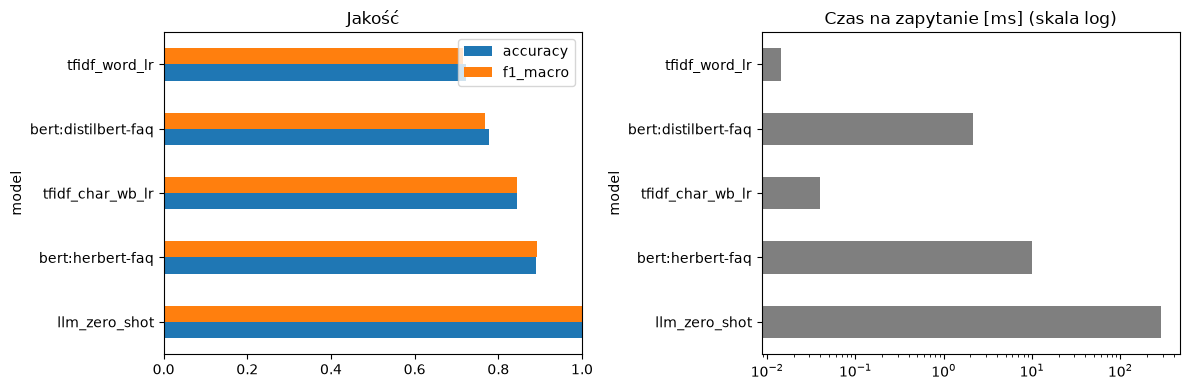

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
cmp.plot.barh(x="model", y=["accuracy", "f1_macro"], ax=ax[0]); ax[0].set_xlim(0, 1); ax[0].set_title("Jakość")
cmp.plot.barh(x="model", y="latency_ms_per_query", ax=ax[1], logx=True, legend=False, color="tab:gray")
ax[1].set_title("Czas na zapytanie [ms] (skala log)"); plt.tight_layout(); plt.show()

## Macierz pomyłek: HerBERT

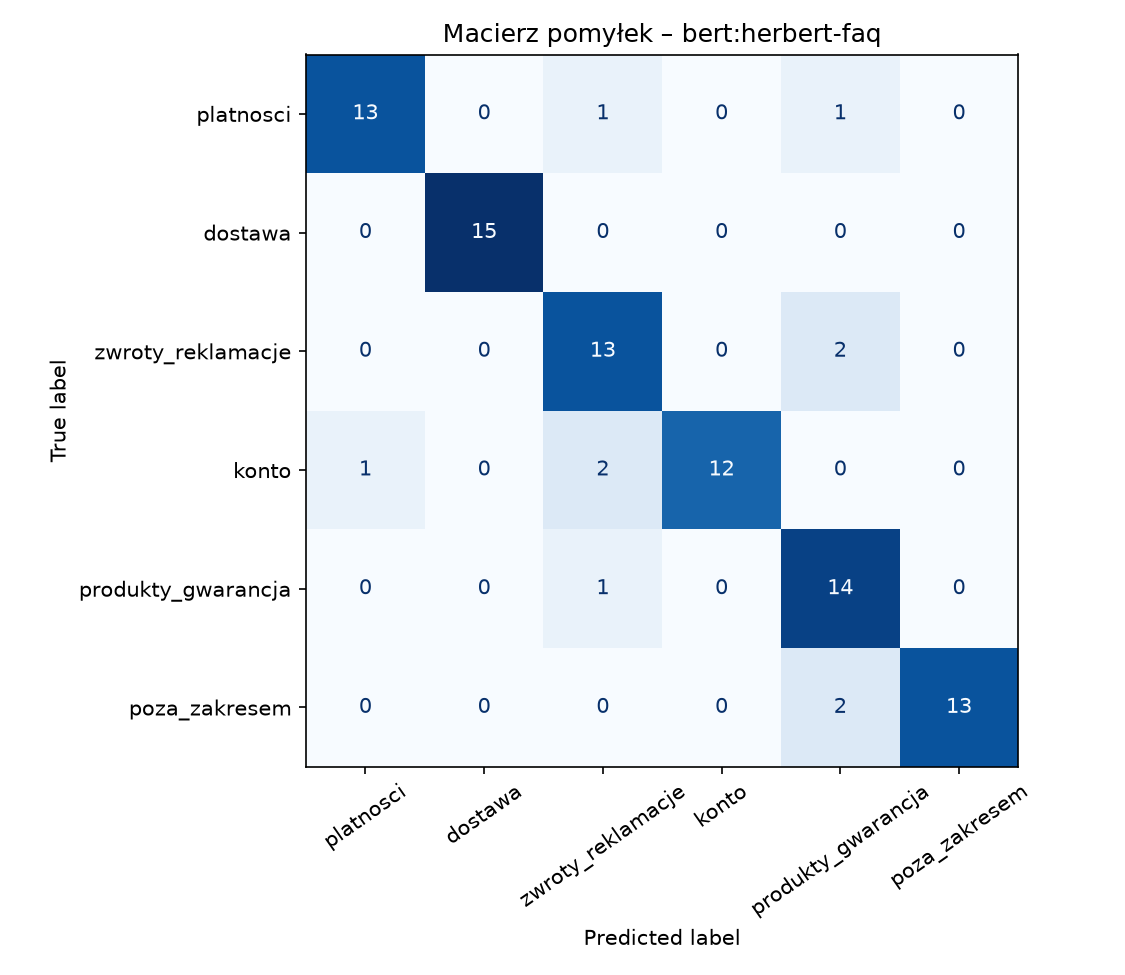

In [5]:
display(Image(f"{R}/confusion_bert_herbert-faq.png", width=520))

## Analiza błędów

In [6]:
err = pd.read_csv(f"{R}/errors.csv")
print(err.groupby("model").size().rename("liczba błędów").to_string())
err[err.model.str.contains("herbert")][["text", "true", "pred"]]

model
bert:distilbert-faq    20
bert:herbert-faq       10
tfidf_char_wb_lr       14
tfidf_word_lr          25


,text,true,pred
39,"chce kupic laptopa za 4 tys na raty, ile rat m...",platnosci,produkty_gwarancja
40,kiedy oddacie mi pieniądze za zwrócony telefon,platnosci,zwroty_reklamacje
41,"Laptop po tygodniu nie włącza się, jak go zare...",zwroty_reklamacje,produkty_gwarancja
42,Chcę zamienić kupionego czarnego iPhone'a na b...,zwroty_reklamacje,produkty_gwarancja
43,Ile mam punktów i na co mogę je wymienić?,konto,zwroty_reklamacje
44,"Dostałem SMS z linkiem do dopłaty 1,99 zł podo...",konto,platnosci
45,Gdzie są moje stare faktury i zamówienia?,konto,zwroty_reklamacje
46,"Ukradli mi telefon, mam Ochronę+ – coś mi przy...",produkty_gwarancja,zwroty_reklamacje
47,ile lat zyje zolw,poza_zakresem,produkty_gwarancja
48,jak wymienic olej w samochodzie,poza_zakresem,produkty_gwarancja


In [7]:
# pytania, które myli każdy model (trudne przypadki)
hard = err.groupby("text").model.nunique()
err[err.text.isin(hard[hard >= 3].index)].drop_duplicates("text")[["text", "true", "pred"]]

,text,true,pred
7,Chcę zamienić kupionego czarnego iPhone'a na b...,zwroty_reklamacje,poza_zakresem
9,"kupilem w salonie, moge oddac przez paczkomat?",zwroty_reklamacje,dostawa
11,"Pralka przecieka po 13 miesiącach, kto za to o...",zwroty_reklamacje,platnosci
13,Ile mam punktów i na co mogę je wymienić?,konto,zwroty_reklamacje
14,Gdzie są moje stare faktury i zamówienia?,konto,platnosci
21,ile kosztuje bilet na pociąg do Krakowa,poza_zakresem,dostawa
22,ile lat zyje zolw,poza_zakresem,dostawa
24,jak wymienic olej w samochodzie,poza_zakresem,konto
26,kiedy oddacie mi pieniądze za zwrócony telefon,platnosci,zwroty_reklamacje


## Learning curve: ile danych potrzeba? (jak zad. 2.4 z Lab 2)
Fine-tuning HerBERT na ok. 50 / 100 / 200 / 400 / 800 przykładach (próbkowanie warstwowe, 3 seedy, średnia ± odchylenie)
w porównaniu z TF-IDF na tych samych podzbiorach.

f1_bert        f1_tfidf       
        mean    std     mean    std
size                               
48     0.233  0.026    0.560  0.020
96     0.347  0.046    0.624  0.061
198    0.687  0.038    0.752  0.018
396    0.849  0.029    0.786  0.059
785    0.879  0.012    0.860  0.013

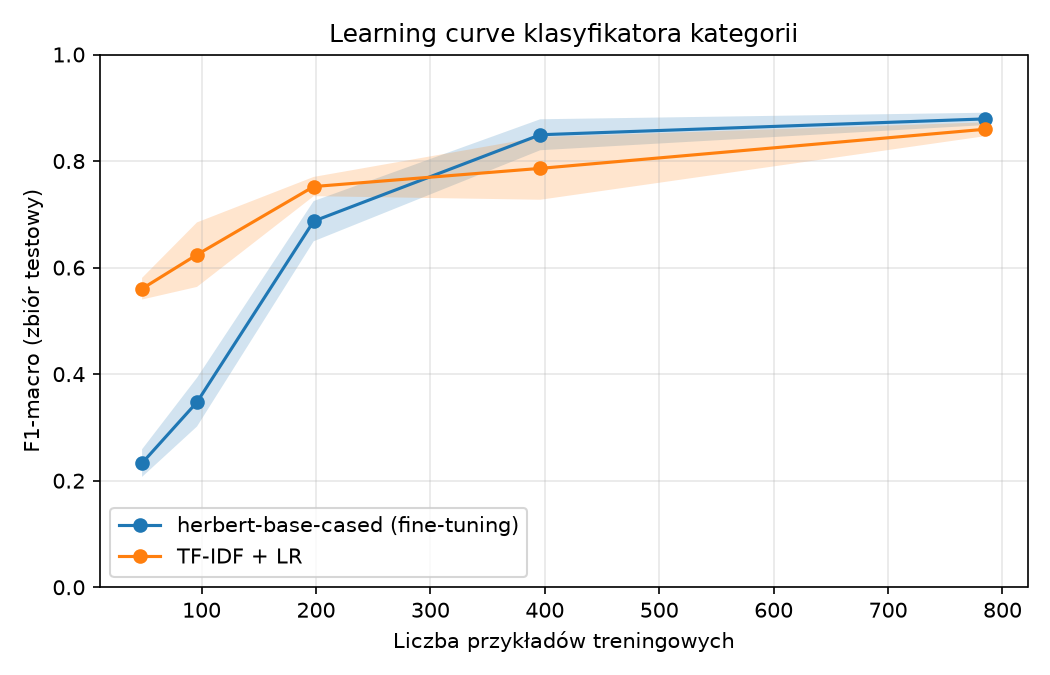

In [8]:
lc = pd.read_csv(f"{R}/learning_curve.csv")
display(lc.groupby("size")[["f1_bert", "f1_tfidf"]].agg(["mean", "std"]).round(3))
display(Image(f"{R}/learning_curve.png", width=560))

## Wnioski
* **HerBERT (fine-tuning)** osiąga F1-macro ≈ 0.89 przy ~10 ms na zapytanie, wystarczająco dobrze i szybko,
  by pełnić rolę routera. Polski model wyraźnie wygrywa z wielojęzycznym DistilBERT (≈ 0.77), znaczenie ma
  słownik i pre-trening na języku docelowym (porównaj Lab 2, gdzie angielski DistilBERT działał na angielskich danych).
* **TF-IDF na n-gramach znakowych** (≈ 0.84) jest zaskakująco mocnym baselinem, n-gramy znakowe są odporne na
  literówki, brak polskich znaków i fleksję. Klasyczny TF-IDF na słowach (jak w Lab 2) jest dużo słabszy (≈ 0.72).
* **LLM zero-shot** klasyfikuje bezbłędnie, ale jest ~30× wolniejszy od HerBERT i wymaga działającego serwera LLM.
  Warto pamiętać, że dane treningowe wygenerował ten sam LLM, a opisy kategorii w prompcie są bardzo precyzyjne.
* **Learning curve:** przy małej liczbie przykładów (≤ 200) fine-tuning przegrywa z TF-IDF, za mało kroków
  optymalizacji, by dostroić 124 mln parametrów. Od ~400 przykładów BERT wyprzedza baseline. Automatyczne
  generowanie danych przez LLM (720 przykładów w ~3,5 min) rozwiązało problem braku danych.
* **Kalibracja:** HerBERT myli się z wysoką pewnością (większość błędów > 0.85), więc próg pewności tylko częściowo
  chroni przed złym routingiem: dlatego dokumenty firmowe są przeszukiwane zawsze, niezależnie od kategorii.
* Większość błędów to pytania leżące na granicy kategorii (np. zwrot pieniędzy: *płatności* czy *zwroty*?).